<a href="https://colab.research.google.com/github/g019-expert/BMEN5801_PS4/blob/main/BMEN5801_PS4_Karthik.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Problem 1

* **No data shown**: Each group is just a bar of the mean, so we can't see  individual measurements, and how spread out they are, if any outliers, and the number of replicates is never given as well. A more honest figure would be a dot plot of every replicate with the mean marked.

* **Broken y axis**: Jumps from 2 to 10 (nM) and uses 2 different scales. Based on the statistical and viz principles, bar height is supposed to show the value and start of axis at 0. But in the given figure the 3rd mutant looks only 2x taller than the 4th  when it is really 15x bigger. Kd goes from ~0.1 to ~14 nM, so a log-scale y-axis w points would show all 4 groups fairly on one scale.

* **Bars not labeled**: There's no x axis labels andlegend so we can't tell which bar is wild-type or which syndrome is which, and all 3 mutants are the same color. colors gray vs purple is only explained in the caption, and the title doesn't say what the result is because as per the principles it is expected of us to label the data directly and write the title like a headline. the p-value lines have no end ticks and also get cut through the 3rd bar, very crowded.

* **Error bars are not defined**: without knowing if they are SD, SEM or 95 CI and the n, we can't judge how much the groups overlap or how sure the result is as those mean different things.

* **Stats not reported properly**: Just says p < 0.05 with no test named,no exact pvalue, no effect size, and no correction for testing 3 comparisons against wild type because as per foundations there is need of control for multiple testing and also look at effect size. For the 4th mutant error bar, a simple p < 0.05  is hard to trust without details as its error bar reaches right down to the top of the wild-type bar


## Problem 2

In [1]:
!git clone https://github.com/g019-expert/BMEN5801_PS4.git

import os

DATA = 'BMEN5801_PS4/data'
RESULTS = 'BMEN5801_PS4/figures'
os.makedirs(RESULTS, exist_ok=True)
print(sorted(os.listdir(DATA)))

Cloning into 'BMEN5801_PS4'...
remote: Enumerating objects: 17, done.
remote: Counting objects: 100% (17/17), done.
remote: Compressing objects: 100% (14/14), done.
remote: Total 17 (delta 1), reused 13 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (17/17), 22.08 MiB | 12.55 MiB/s, done.
Resolving deltas: 100% (1/1), done.
['EMG_musclesynergies.csv', 'PBMC3K.csv', 'breastcancerclinical.csv', 'breastcancerproteomes.csv', 'eegdata.pkl']


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [4]:
proteome = pd.read_csv(f'{DATA}/breastcancerproteomes.csv')
print(proteome.shape)

(12553, 86)


83 samples | 12553 proteins, missing values: 109080
PC1 = 10.6%, PC2 = 6.9% of variance


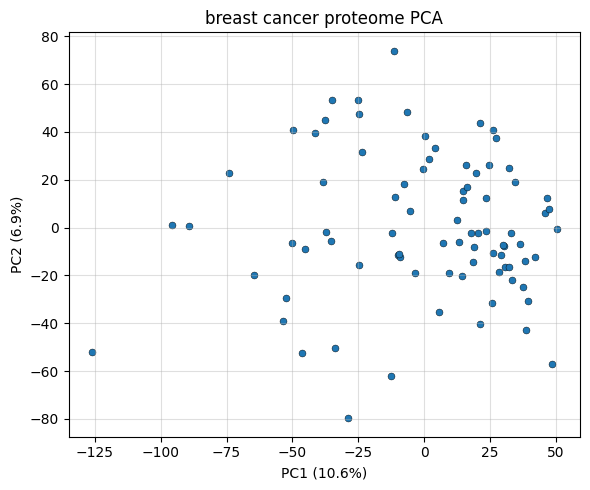

In [5]:
# 2(a)
# samples = rows, proteins = cols
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X = proteome.set_index('RefSeq_accession_number').select_dtypes('number').T
print(f'{X.shape[0]} samples | {X.shape[1]} proteins, missing values: {X.isna().sum().sum()}')

# blanks filled with each protein median across all samples and scaled to <0,1> mean, stdev and then pca
X_imp = SimpleImputer(strategy='median').fit_transform(X)
X_scaled = StandardScaler().fit_transform(X_imp)

pca = PCA(random_state=42).fit(X_scaled)
pcs = pca.transform(X_scaled)
ev = pca.explained_variance_ratio_
print(f'PC1 = {100*ev[0]:.1f}%, PC2 = {100*ev[1]:.1f}% of variance')

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(pcs[:, 0], pcs[:, 1], s=25, edgecolor='k', lw=0.3)
ax.set_xlabel(f'PC1 ({100*ev[0]:.1f}%)')
ax.set_ylabel(f'PC2 ({100*ev[1]:.1f}%)')
ax.set_title('breast cancer proteome PCA')
ax.grid(True, alpha=0.4)
fig.tight_layout()
fig.savefig(f'{RESULTS}/p2a_pca.png', dpi=200, bbox_inches='tight')
plt.show()

First, I flipped the file to samples as rows and  filled the 109080 blanks with each protein median across all samples, then scaled to mean 0, stdev 1 and then ran PCA. PCA kept all 83 components, PC1 explains 10.6% and PC2 6.9% of the variance.

In [7]:
# 2(b)
# cumulative explained variance accounted for first 10 pc's
cum = np.cumsum(ev)
print('cumulative expained variance, PC<1-10>:', ', '.join(f'{100*c:.1f}' for c in cum[:10]))
print(f'PCs needed for 50%: {np.argmax(cum >= 0.5) + 1}, 80%: {np.argmax(cum >= 0.8) + 1}, 90%: {np.argmax(cum >= 0.9) + 1} | from a total of {len(ev)}')

cumulative expained variance, PC<1-10>: 10.6, 17.6, 23.8, 27.7, 30.9, 34.1, 36.5, 38.7, 40.8, 42.9
PCs needed for 50%: 15, 80%: 45, 90%: 60 | from a total of 83


First 10 PCs explain 42.9% of the total variance. Every PC after PC1 and PC2  only account for small variation. The first 10 PCs explain less than half of the variation in the proteome. Variance is spread over many components instead of packed in a few becaue it takes 15 PCs to reach 50%, 45 to reach 80% and 60 of the 83 to reach 90%. With about 12,500 proteins and only 83 samples, the proteomes differ in a lot of independent ways, so the 2D plot from 2(a) only shows a small part of the picture and patterns could be hidden in the other PCs.


{'Positive': 54, 'Negative': 26, nan: 3}
PC1: median ER positive = 12.8, ER negative = 14.7, p = 9.5e-01
PC2: median ER positive = -6.9, ER negative = 9.9, p = 8.9e-03


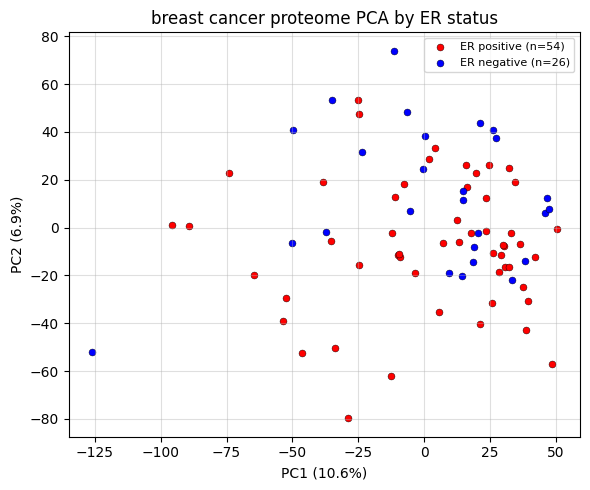

In [9]:
# 2(c)
# AO-A12D.01TCGA to clinical TCGA-AO-A12D then ER status
from scipy import stats

clinical = pd.read_csv(f'{DATA}/breastcancerclinical.csv')
ids = 'TCGA-' + X.index.str.replace(r'\.\d+TCGA$', '', regex=True)
er = pd.Series(ids, index=X.index).map(clinical.set_index('Sample')['ER Status'])
print(er.value_counts(dropna=False).to_dict())   # no clinical record for 3 CPTAC samples

# ER status vs the samples along PC1 or PC2 relation (mann whitney, refereced stat foundtions lecture)
pos, neg = (er == 'Positive').values, (er == 'Negative').values
for i in range(2):
    p = stats.mannwhitneyu(pcs[pos, i], pcs[neg, i]).pvalue
    print(f'PC{i+1}: median ER positive = {np.median(pcs[pos, i]):.1f}, ER negative = {np.median(pcs[neg, i]):.1f}, p = {p:.1e}')

fig, ax = plt.subplots(figsize=(6, 5))
for mask, col, lbl in [(pos, 'red', 'ER positive'), (neg, 'blue', 'ER negative')]:
    ax.scatter(pcs[mask, 0], pcs[mask, 1], s=25, c=col, edgecolor='k', lw=0.3, label=f'{lbl} (n={mask.sum()})')
ax.set_xlabel(f'PC1 ({100*ev[0]:.1f}%)')
ax.set_ylabel(f'PC2 ({100*ev[1]:.1f}%)')
ax.set_title('breast cancer proteome PCA by ER status')
ax.grid(True, alpha=0.4)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(f'{RESULTS}/p2c_pca_er.png', dpi=200, bbox_inches='tight')
plt.show()

ER positive and ER negative samples overlap a lot so ER status is not the main  driving factor for the proteome difference. PC1 which is the biggest source of variation, doesn't separate them at all because of its median for ER pos and neg and p value. There is a partial split along PC2 where ER negative sample sit above, and most samples at the top of the plot are ER negative and the bottom mostly ER positive. Thereforre, ER status is linked to part of the proteome, along the PC2 direction, but it only explains a small piece of the overall differences between tumors.


## Problem 3

In [11]:
eeg = pd.read_pickle(f'{DATA}/eegdata.pkl')
t = eeg['Time'].values
electrodes = eeg.drop(columns='Time')
print(electrodes.shape, f'{t[-1]:.1f} s at {1/np.median(np.diff(t)):.0f} Hz')

(50000, 97) 47.7 s at 1049 Hz


followed same ICA procedure explained from class which is to scale electroed and then FastICA

/usr/local/lib/python3.13/dist-packages/sklearn/decomposition/_fastica.py:127: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum number of iterations.
  warnings.warn(


Converged in 5000 iterations
Correlation with electrode 1: IC1 +0.23, IC2 +0.07, IC3 -0.15, IC4 -0.03, IC5 +0.04, IC6 +0.16, IC7 +0.04, IC8 +0.16, IC9 -0.01, IC10 +0.92


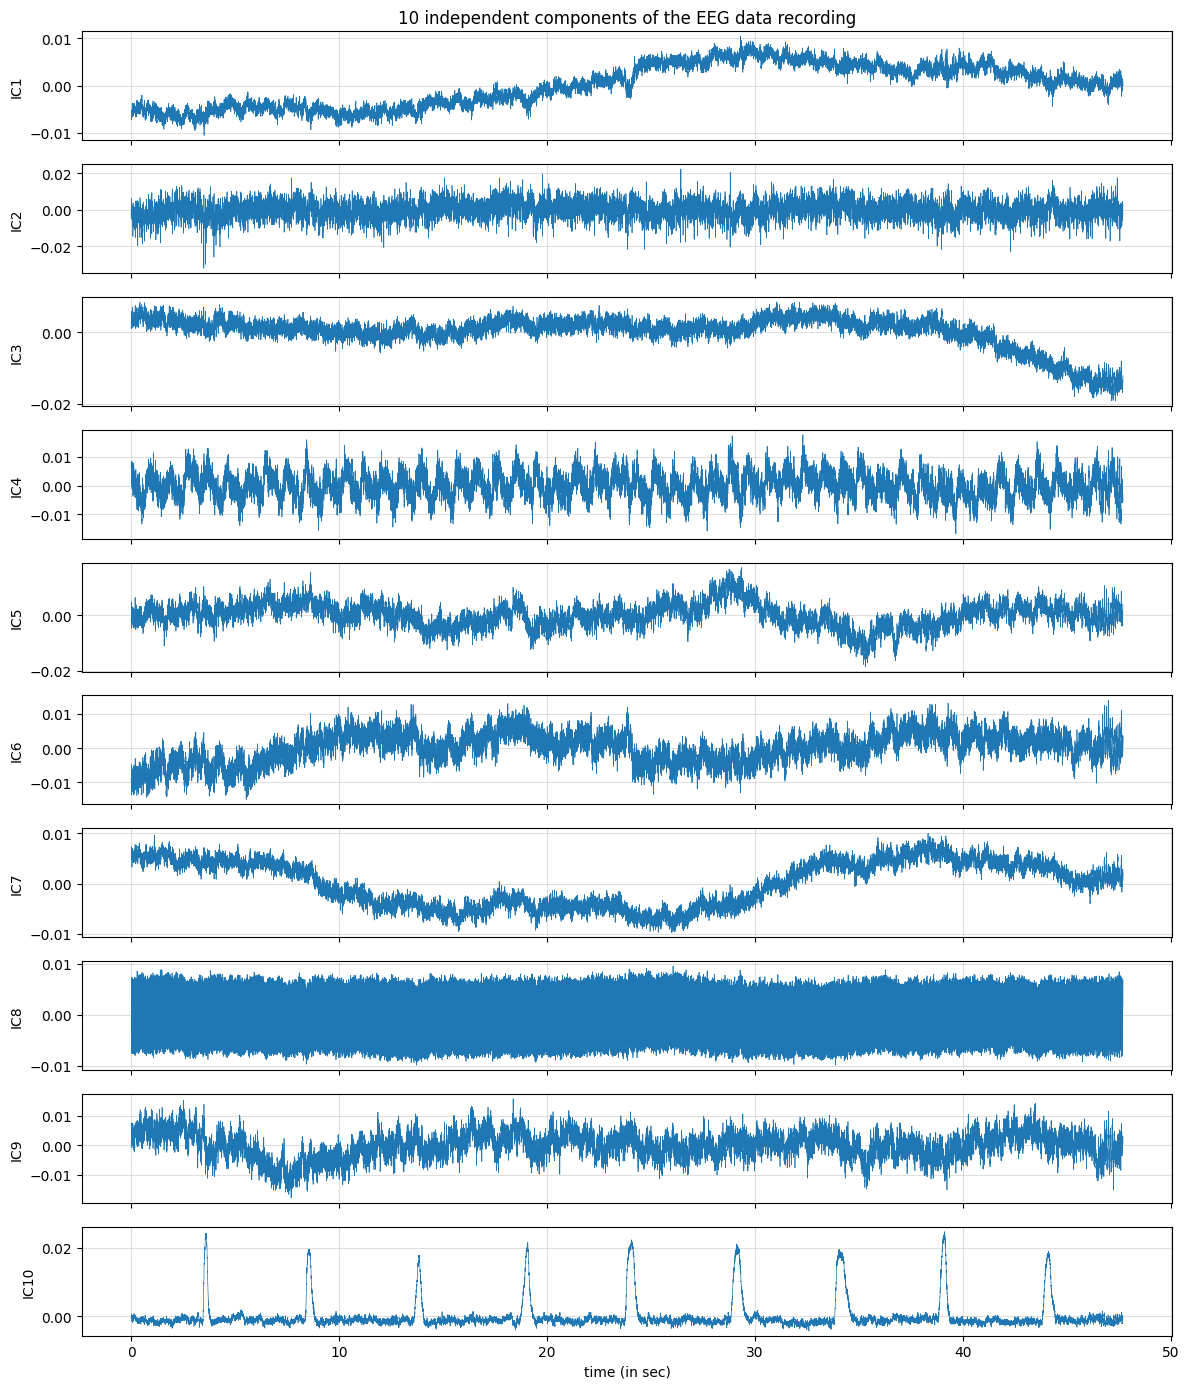

In [12]:
# 3(a)
# scale eand then FastICA with 10 components
from sklearn.decomposition import FastICA
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler().fit(electrodes)
eeg_scaled = scaler.transform(electrodes)
ica = FastICA(n_components=10, whiten='arbitrary-variance', max_iter=5000, random_state=0)
sources = ica.fit_transform(eeg_scaled)
print(f'Converged in {ica.n_iter_} iterations')

# blink check (corr of each comp with elec 1)
r = [np.corrcoef(sources[:, k], electrodes['Ch 0'])[0, 1] for k in range(10)] # ch 0 is elec 1
print('Correlation with electrode 1:', ', '.join(f'IC{k+1} {v:+.2f}' for k, v in enumerate(r)))

fig, axes = plt.subplots(10, 1, figsize=(12, 14), sharex=True)
for k, ax in enumerate(axes):
    ax.plot(t, sources[:, k], lw=0.5)
    ax.set_ylabel(f'IC{k+1}')
    ax.grid(True, alpha=0.4)
axes[0].set_title('10 independent components of the EEG data recording')
axes[-1].set_xlabel('time (in sec)')
fig.tight_layout()
fig.savefig(f'{RESULTS}/p3a_ica_components.png', dpi=150, bbox_inches='tight')
plt.show()

component IC10 has the eyeblink artifact. From analysis its flat except for 9 sharp peaks roughly at the same 9 blinks in electrode 1, and its the only component that closely tracks electrode 1 (beause of a correlation of +0.92 whereas all others between -0.15 to +0.23). the other components look like  steady noise, or could be just brain activity with no blink peaks

blink component: IC10
electrode 1 max: 294 -> 93, SD: 42.8 -> 17.0


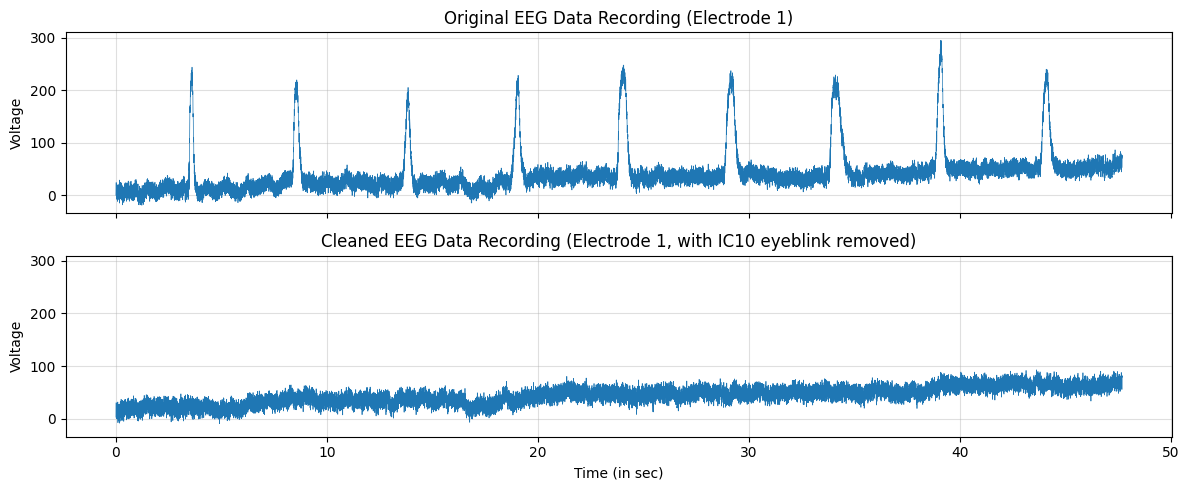

In [13]:
# 3(b)
# remove the component with eyeblink artifact across all electrode
blink = int(np.argmax(np.abs(r)))
print(f'blink component: IC{blink+1}')

blink_part = np.outer(sources[:, blink], ica.mixing_[:, blink])
eeg_clean = pd.DataFrame(scaler.inverse_transform(eeg_scaled - blink_part), columns=electrodes.columns)

e1, e1_clean = electrodes['Ch 0'], eeg_clean['Ch 0']
print(f'electrode 1 max: {e1.max():.0f} -> {e1_clean.max():.0f}, SD: {e1.std():.1f} -> {e1_clean.std():.1f}')

fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True, sharey=True)
axes[0].plot(t, e1, lw=0.5)
axes[0].set_title('Original EEG Data Recording (Electrode 1)')
axes[1].plot(t, e1_clean, lw=0.5)
axes[1].set_title(f'Cleaned EEG Data Recording (Electrode 1, with IC{blink+1} eyeblink removed)')
for ax in axes:
    ax.set_ylabel('Voltage')
    ax.grid(True, alpha=0.4)
axes[-1].set_xlabel('Time (in sec)')
fig.tight_layout()
fig.savefig(f'{RESULTS}/p3b_eeg_cleaned.png', dpi=150, bbox_inches='tight')
plt.show()

## Problem 4

In [14]:
emg = pd.read_csv(f'{DATA}/EMG_musclesynergies.csv')
t_emg = emg['X [s]']
muscles = emg.drop(columns='X [s]')
# col names changed for exampel, R TIBIALIS ANTERIOR: EMG 1->MAV [Volts] becomes 'R Tibialis Anterior'
muscles.columns = [c.split(':')[0].title() for c in muscles.columns]
print(muscles.shape, f'{t_emg.iloc[-1]:.1f} sec at {1/np.median(np.diff(t_emg)):.0f} Hz, min value = {muscles.values.min():.1e}')

(969, 12) 60.4 sec at 16 Hz, min value = 0.0e+00


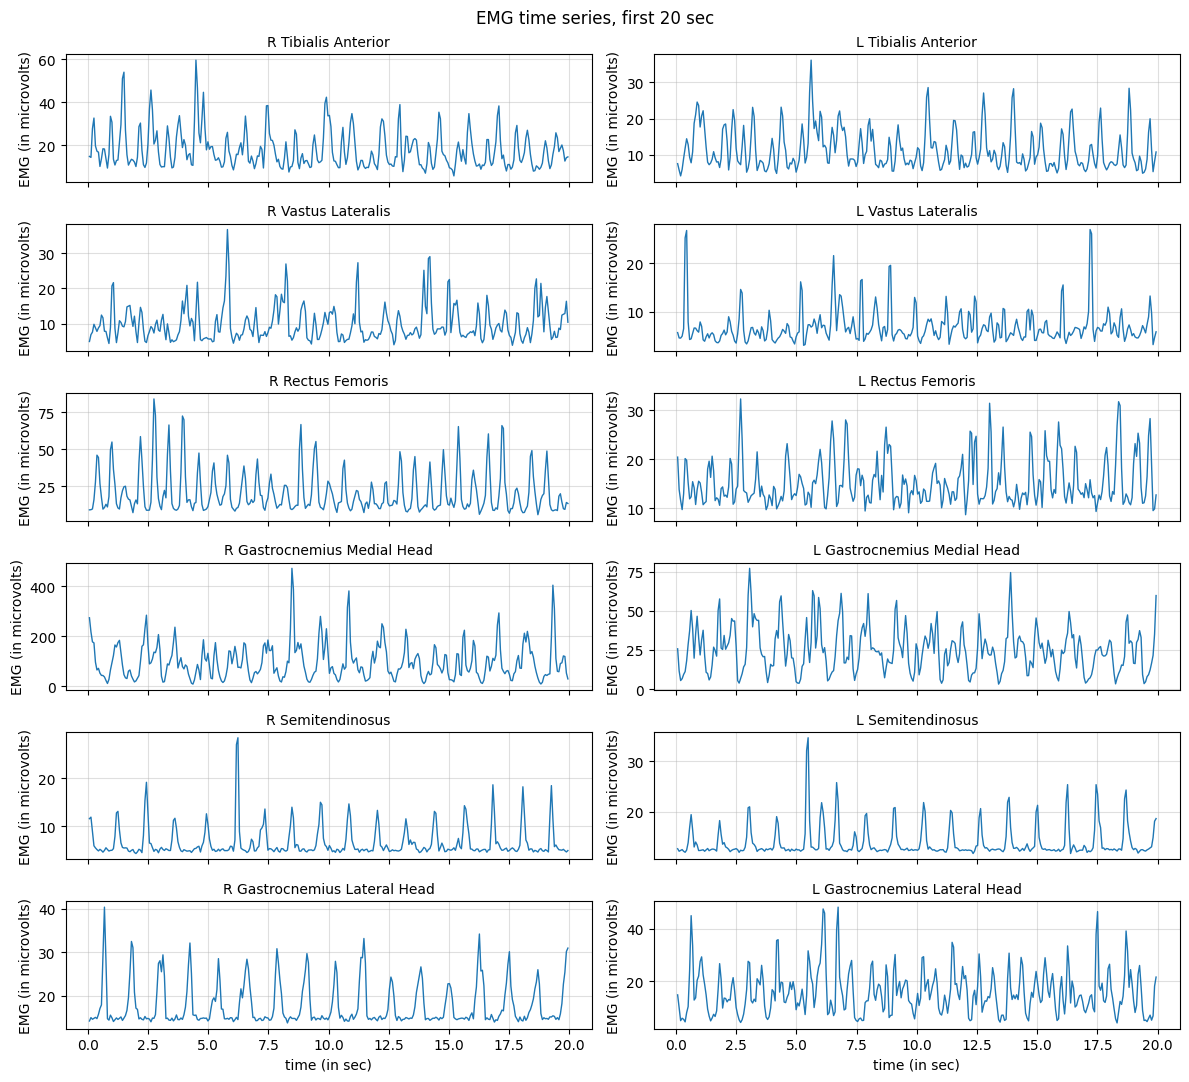

In [16]:
# 4(a)
# first 20 s of emg time series for each muscle
first20 = t_emg <= 20
fig, axes = plt.subplots(6, 2, figsize=(12, 11), sharex=True)
for k, (name, ax) in enumerate(zip(muscles.columns, axes.ravel())):
    ax.plot(t_emg[first20], 1e6*muscles.loc[first20, name], lw=1)
    ax.set_title(name, fontsize=10)
    ax.set_ylabel('EMG (in microvolts)')
    ax.grid(True, alpha=0.4)
for ax in axes[-1]:
    ax.set_xlabel('time (in sec)')
fig.suptitle('EMG time series, first 20 sec')
fig.tight_layout()
fig.savefig(f'{RESULTS}/p4a_emg_first20s.png', dpi=150, bbox_inches='tight')
plt.show()

R gastrocnmius medial head is bigger than every other muscle

In [19]:
# 4(b)
from sklearn.decomposition import NMF
from sklearn.metrics import r2_score

# 12 muscles x 969 time points
emg_norm = (muscles / muscles.max()).T.values
nmf = NMF(n_components=4, init='nndsvda', max_iter=1000, random_state=42)
W = nmf.fit_transform(emg_norm)
H = nmf.components_
emg_hat = W @ H

# VAF is error vs the total signal and R2 is error vs each muscle self mean
sse = ((emg_norm - emg_hat)**2).sum()
vaf = 1 - sse / (emg_norm**2).sum()
r2 = r2_score(emg_norm.T, emg_hat.T, multioutput='variance_weighted')
print(f'Space with 4 components: VAF = {100*vaf:.1f}%, R2 = {r2:.3f}')

Space with 4 components: VAF = 94.1%, R2 = 0.643


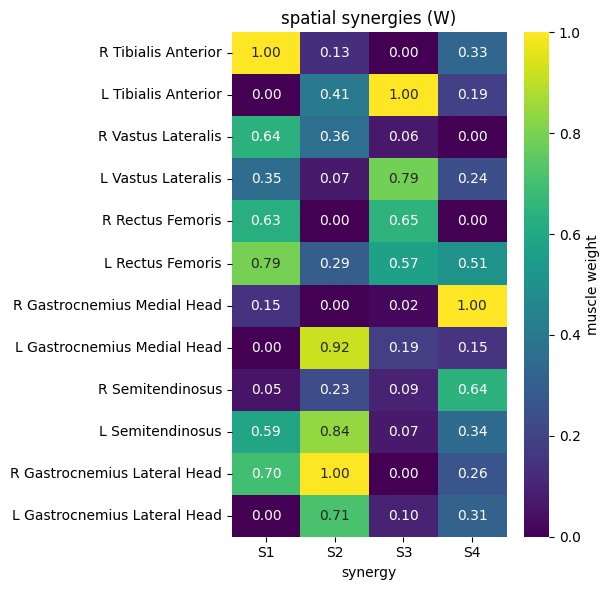

In [20]:
# 4(c)
# heatmap of spatial synergies basis matrix W
W_norm = pd.DataFrame(W / W.max(axis=0), index=muscles.columns, columns=[f'S{k+1}' for k in range(4)])

fig, ax = plt.subplots(figsize=(6, 6))
# all synergy scaled to its strongest muscle (=1) or ease of compariosn
sns.heatmap(W_norm, annot=True, fmt='.2f', cmap='viridis', vmin=0, vmax=1, cbar_kws={'label': 'muscle weight'}, ax=ax)
ax.set_xlabel('synergy')
ax.set_ylabel('')
ax.set_title('spatial synergies (W)')
fig.tight_layout()
fig.savefig(f'{RESULTS}/p4c_synergy_heatmap.png', dpi=200, bbox_inches='tight')
plt.show()

the synergies show up as the bright blocks in each column, and they split by leg and also by front or back of the leg.
* S1 = right front (R Tibialis Anterior, R Vastus Lateralis, R Rectus Femoris)
* S3 = left front (L Tibialis Anterior, L Vastus Lateralis, L Rectus Femoris)
* S4 = right back (R Gastrocnemius Medial, R Semitendinosus)
* S2 = left back (L Gastrocnemius Medial + Lateral, L Semitendinosus). so the 12 muscles work as 4 groups that alternate left and right

## Problem 5

In [21]:
pbmc = pd.read_csv(f'{DATA}/PBMC3K.csv')
X_pc = pbmc.drop(columns='CellType').values
cell_type = pbmc['CellType']
print(X_pc.shape, cell_type.value_counts().to_dict())

(2638, 50) {'CD4 T cells': 1144, 'CD14+ Monocytes': 480, 'B cells': 342, 'CD8 T cells': 316, 'NK cells': 154, 'FCGR3A+ Monocytes': 150, 'Dendritic cells': 37, 'Megakaryocytes': 15}


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


t-SNE: trustworthiness = 0.919, silhouette = 0.444
UMAP: trustworthiness = 0.861, silhouette = 0.569


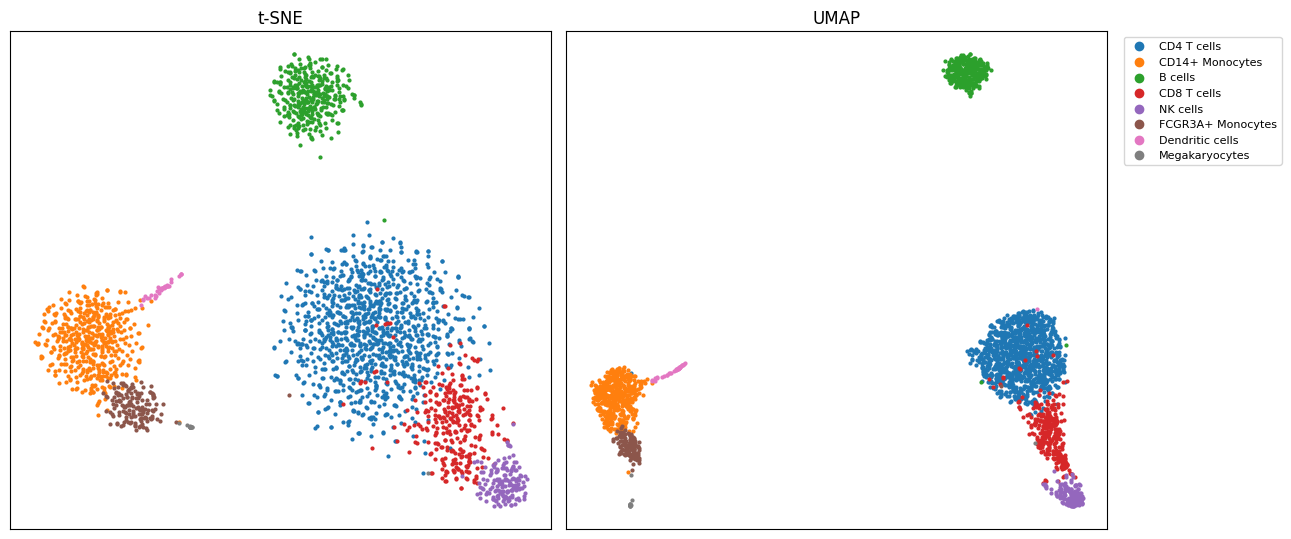

In [22]:
# 5(a)
# t-SNE vs UMAP (seed42) on the 50 PCs
# trustworthiness and silhouette
from sklearn.manifold import TSNE, trustworthiness
from sklearn.metrics import silhouette_score
import umap

emb = {'t-SNE': TSNE(n_components=2, random_state=42).fit_transform(X_pc),
       'UMAP': umap.UMAP(n_components=2, random_state=42).fit_transform(X_pc)}
for name, e in emb.items():
    print(f'{name}: trustworthiness = {trustworthiness(X_pc, e):.3f}, silhouette = {silhouette_score(e, cell_type):.3f}')

types = cell_type.value_counts().index
colors = dict(zip(types, sns.color_palette('tab10', len(types))))
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, (name, e) in zip(axes, emb.items()):
    for ct in types:
        m = (cell_type == ct).values
        ax.scatter(e[m, 0], e[m, 1], s=4, color=colors[ct], label=ct)
    ax.set_title(name)
    ax.set_xticks([]); ax.set_yticks([])
axes[1].legend(markerscale=3, fontsize=8, bbox_to_anchor=(1.02, 1), loc='upper left')
fig.tight_layout()
fig.savefig(f'{RESULTS}/p5a_tsne_umap.png', dpi=200, bbox_inches='tight')
plt.show()

UMAP gave better separation between biologicalcell populations. Silhouette is higher, so the cell types form tighter clusters with more space in between them (proven also from above 3 compact far off islands). t-SNE has higher trustworthiness , so it keeps each cell nearest neighbors a bit more faithfully, but clusters are looser and more spread out.

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


       trustworthiness        silhouette       
method            UMAP  t-SNE       UMAP  t-SNE
value                                          
5                0.868  0.916      0.532  0.291
15               0.861  0.921      0.569  0.374
30               0.862  0.919      0.558  0.444
60               0.860  0.901      0.548  0.490
100              0.860  0.889      0.538  0.499


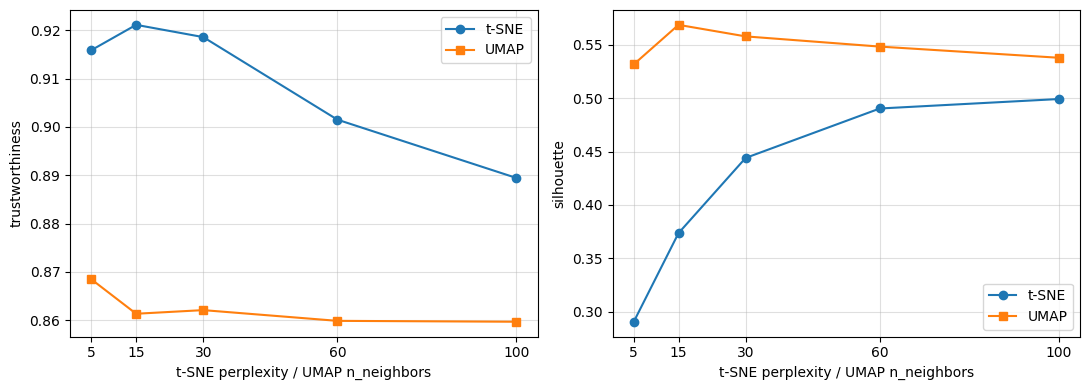

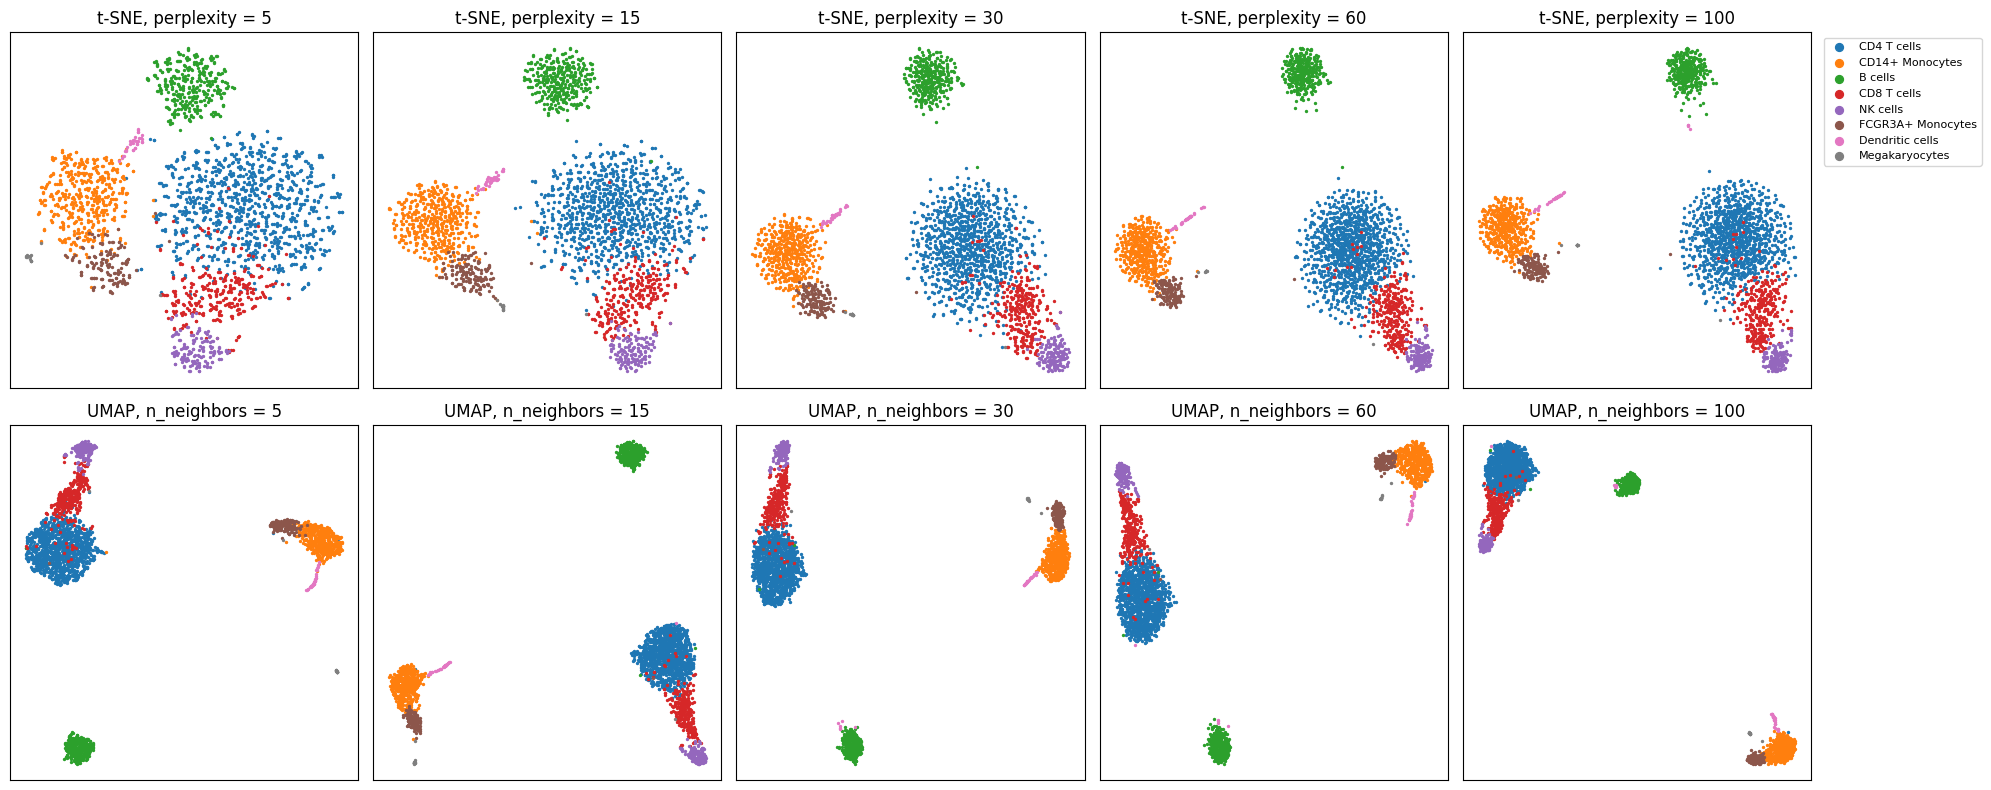

In [23]:
# 5(b)
values = [5, 15, 30, 60, 100]
rows, sweep = [], {}
for v in values:
    for name, model in [('t-SNE', TSNE(n_components=2, perplexity=v, random_state=42)), ('UMAP', umap.UMAP(n_components=2, n_neighbors=v, random_state=42))]:
        e = model.fit_transform(X_pc)
        sweep[(name, v)] = e
        rows.append({'method': name, 'value': v, 'trustworthiness': trustworthiness(X_pc, e), 'silhouette': silhouette_score(e, cell_type)})
scores = pd.DataFrame(rows)
print(scores.pivot(index='value', columns='method', values=['trustworthiness', 'silhouette']).round(3))

#  hyperparameter and scores
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric in zip(axes, ['trustworthiness', 'silhouette']):
    for name, mk in [('t-SNE', 'o'), ('UMAP', 's')]:
        s = scores[scores['method'] == name]
        ax.plot(s['value'], s[metric], marker=mk, label=name)
    ax.set_xlabel('t-SNE perplexity / UMAP n_neighbors')
    ax.set_ylabel(metric)
    ax.set_xticks(values)
    ax.grid(True, alpha=0.4)
    ax.legend()
fig.tight_layout()
fig.savefig(f'{RESULTS}/p5b_scores.png', dpi=200, bbox_inches='tight')
plt.show()

# 2d t-SNE and UMAP embeddings
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
for i, name in enumerate(['t-SNE', 'UMAP']):
    for j, v in enumerate(values):
        ax, e = axes[i, j], sweep[(name, v)]
        for ct in types:
            m = (cell_type == ct).values
            ax.scatter(e[m, 0], e[m, 1], s=2, color=colors[ct], label=ct)
        ax.set_title(f"{name}, {'perplexity' if name == 't-SNE' else 'n_neighbors'} = {v}")
        ax.set_xticks([]); ax.set_yticks([])
axes[0, -1].legend(markerscale=4, fontsize=8, bbox_to_anchor=(1.02, 1), loc='upper left')
fig.tight_layout()
fig.savefig(f'{RESULTS}/p5b_embeddings.png', dpi=150, bbox_inches='tight')
plt.show()

* t-SNE perplexity changes the  structure of cluster by a lot. From observing above embeddings, at low perplexity (like at 5) t-SNE only looks at a few close neighbors, so each cell type is spread out loosely with very little space between groups. As perplexity goes up it looks at more neighbors, and so clusters get tighter and more separate (silhoutte increased), but trustworthiness drops  because fine local detail gets traded for overall grouping in larger picture.

* UMAP n_neighbors changes the structure barely. Silhouette stays consistent and trustworthiness too across all values, and the plots always show the same 3 islands. Larger n_neighbors just packs each island a bit more tighter

So, t-SNE depends a lot on the perplexity we pick, while UMAP stays stable. UMAP separates the cell types better at every setting becaue of higher silhouette, and t-SNE keeps local neighbors better at every setting because of higher trustworthiness